# Figures for papers: redshift (z) distribution
Stephanie Juneau (NSF NOIRLab) on behalf of the AGN/Gal VAC team and GQP working group

We use this notebook to generate plots for the AGN/Galaxy Classification VAC paper. This is the DR1 version.

In [1]:
# Numpy
import numpy as np
# Plotting stuff and suppressing boring warnings
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
import warnings
warnings.filterwarnings('ignore')

# For Venn diagram (may need to pip install matplotlib_venn)
from matplotlib_venn import venn3

# Get the GQP code
import sys
# Set the path where the py scripts are
sys.path.append("../py/")
import set_agn_masksDESI
from set_agn_masksDESI import get_agn_maskbits

# DESI targeting masks 
from desitarget import targetmask            # For Main survey
from desitarget.sv1 import sv1_targetmask    # For SV1
from desitarget.sv2 import sv2_targetmask    # For SV2
from desitarget.sv3 import sv3_targetmask    # For SV3

## SJ: Check if we're using this?!
import fitsio

# Import Astropy libraries - useful for many astronomy related function
from astropy.table import Table #, join, Column
from astropy.io import fits

# TO DO: simplify/clean this?
settings = {
    'font.size':11,
    'axes.linewidth':1.5,
    'xtick.major.size':6.0,
    'xtick.minor.size':4.0,
    'xtick.major.width':1.0,
    'xtick.minor.width':1.,
    'xtick.direction':'in', 
    'xtick.minor.visible':True,
    'xtick.top':True,
    'ytick.major.size':6.0,
    'ytick.minor.size':4.0,
    'ytick.major.width':1.0,
    'ytick.minor.width':1.,
    'ytick.direction':'in', 
    'ytick.minor.visible':True,
    'ytick.right':True,
    'axes.labelsize':11
    }

plt.rcParams.update(**settings)

## Read data

In [2]:
def return_catdir(location='nersc'):

    dl_path = '~/data/data_DESI/science/gqp/agncatalog/catalog/'
    nersc_path = '/global/cfs/cdirs/desi/science/gqp/agncatalog/dr1/v1.0/'
    if location=='datalab':
        return(dl_path)
    else:
        return(nersc_path)  #default

In [3]:
catdir = return_catdir(location='datalab')
#filename = f'{catdir}agngal_dr1_20260709.fits'
filename = f'{catdir}desi_agngal_iron_v20260903.fits' # FSF v4.0 VAC

# UPDATE this if running at NERSC or by someone else!
figdir = '/dlusers/sjuneau_user/data/data_DESI/figs/agngal_dr1/'

# Open the catalog
agn_hdul = fits.open(filename, format='fits')
agn_hdul.info()

Filename: /home/jail/./dlusers/sjuneau_user/data/data_DESI/science/gqp/agncatalog/catalog/desi_agngal_iron_v20260903.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       6   ()      
  1  AGNCAT        1 BinTableHDU    101   17995896R x 42C   [K, 7A, 6A, J, D, K, D, D, D, D, E, E, D, 6A, K, K, K, J, D, D, K, D, D, D, I, E, L, L, L, K, K, K, K, K, K, K, K, K, K, K, K, K]   
  2  AUXDATA       1 BinTableHDU    200   17995896R x 67C   [E, K, 7A, 6A, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E]   


In [4]:
%%time
# Load the catalog into Astropy tables
#T = Table(agn_hdul[1].data)
#T2 = Table(agn_hdul[2].data)
T = Table(fitsio.read(filename, ext=1))
T2 = Table(fitsio.read(filename, ext=2))

CPU times: user 24.1 s, sys: 7.03 s, total: 31.1 s
Wall time: 3min 9s


In [5]:
AGN_MASKBITS, OPT_UV_TYPE, IR_TYPE = get_agn_maskbits('../py/agnmask.yaml')

In [6]:
#T.colnames

## Define functions and color scheme

In [7]:
## Default color scheme

# Color maps
cmap_sf = 'Blues'
cmap_sy = 'Greens'
#cmap_sy = 'Reds'
#cmap_cp = 'Greys'
cmap_cp = 'Oranges'
cmap_lin = 'Purples'
cmap_ret = 'PuRd' #'YlOrBr'
cmap_pass = 'Greys' # make sure it differs from composite

# Color names for labels or lines
col_sf = 'tab:blue'
col_sy = 'seagreen'
#col_sy = 'darkred' #'crimson'
#col_cp = 'grey'
col_cp = 'orangered'
col_lin = 'rebeccapurple'
col_ret = 'purple' #'gold'
col_pass = 'grey'  # make sure it differs from composite

## Redshift distribution (3-panel figure)

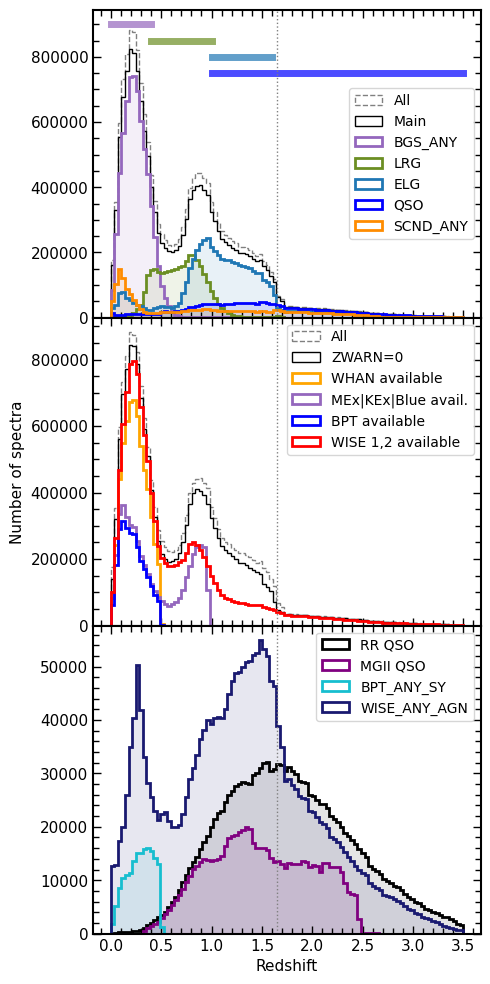

In [8]:
#agntypes = ['RR', 'MGII', 'QN', 'QN_BGS', 'QN_ELG', 'BPT_ANY_SY', 'OPT_OTHER_AGN', 'WISE_ANY_AGN']
#agnlabels = ['RR QSO', 'MGII QSO', 'QN (QSO)', 'QN_BGS', 'QN_ELG', 'BPT_ANY_SY', 'OPT_OTHER_AGN', 'WISE_ANY_AGN']
#colors = ['red', 'purple', 'tab:purple', 'tab:cyan', 'tab:blue', 'blue', 'green', 'black']

agntypes = ['RR', 'MGII', 'BPT_ANY_SY', 'WISE_ANY_AGN']
agnlabels = ['RR QSO', 'MGII QSO', 'BPT_ANY_SY', 'WISE_ANY_AGN']
colors = ['black', 'purple', 'tab:cyan', 'midnightblue']

# OPT_OTHER_AGN is not confident enough (includes composite, weak AGN, etc.); treat separately
opt_other_agn_secure = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.MEX_AGN != 0)
#opt_other_agn_secure = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.MEX_AGN != 0)|(T['OPT_UV_TYPE'] & OPT_UV_TYPE.KEX_AGN != 0)

desi_mask = targetmask.desi_mask
is_main = T['SURVEY']=='main'
targets = ['BGS_ANY','LRG','ELG','QSO','SCND_ANY']
target_colors = ['tab:purple', 'olivedrab', 'tab:blue', 'blue', 'darkorange']
#target_colors = ['tab:purple', 'red', 'tab:blue', 'blue', 'orange']
desi_target = T['DESI_TARGET']

# Plot
fig, (ax0, ax1, ax2) = plt.subplots(3, 1, figsize=(5,12), sharex=True)
plt.subplots_adjust(hspace=0)

rz = (0,3.5)

# Left-hand panel: full catalog
ax0.hist(T['Z'],bins=100,range=(rz), histtype='step', lw=1, color='gray', ls='--', label='All')
ax0.hist(T['Z'][is_main],bins=100,range=(rz), histtype='step', lw=1, color='k', label='Main')

# Broken per target class
for i, tclass in enumerate(targets):
    sel = is_main & (T['DESI_TARGET'] & desi_mask[tclass] !=0)
    col = target_colors[i]
    ax0.hist(T['Z'][sel],bins=100,range=(rz), alpha=0.1, color=col)
    ax0.hist(T['Z'][sel],bins=100,range=(rz), histtype='step', lw=2, color=col, label=tclass)

# Middle panel: full catalog + only secure redshifts
ax1.hist(T['Z'],bins=100,range=(rz), histtype='step', lw=1, color='gray', ls='--', label='All')
ax1.hist(T['Z'][T['ZWARN']==0],bins=100,range=(rz), histtype='step', lw=1, color='k', label='ZWARN=0')

# WHAN available
ax1.hist(T['Z'][(T['ZWARN']==0)&(T['OPT_UV_TYPE'] & OPT_UV_TYPE.WHAN != 0)],bins=100,range=(rz), 
         histtype='step', lw=2, color='orange', label='WHAN available')

# MEx/KEx/Blue available (all go roughly to z~1)
avail_z1 = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.MEX != 0) | (T['OPT_UV_TYPE'] & OPT_UV_TYPE.KEX != 0) | (T['OPT_UV_TYPE'] & OPT_UV_TYPE.BLUE != 0)
ax1.hist(T['Z'][(T['ZWARN']==0)&(avail_z1)],bins=100,range=(rz), 
         histtype='step', lw=2, color='tab:purple', label='MEx|KEx|Blue avail.')

# BPT available
ax1.hist(T['Z'][(T['ZWARN']==0)&(T['OPT_UV_TYPE'] & OPT_UV_TYPE.NII_BPT != 0)],bins=100,range=(rz), 
         histtype='step', lw=2, color='b', label='BPT available')

# WISE (W1, W2) available [some diagrams need W1, W2, W3]
ax1.hist(T['Z'][(T['ZWARN']==0)&(T['IR_TYPE'] & IR_TYPE.WISE_W12 != 0)],bins=100,range=(rz), 
         histtype='step', lw=2, color='r', label='WISE 1,2 available')

# Right-hand panel: selected classes of AGN/QSO
for i, agn in enumerate(agntypes):
    sel = (T['AGN_MASKBITS'] & AGN_MASKBITS[agn] != 0)
    col = colors[i]
    ax2.hist(T['Z'][sel],bins=100,range=(rz), alpha=0.1, color=col)
    ax2.hist(T['Z'][sel],bins=100,range=(rz), label=agnlabels[i], histtype='step', lw=2, color=col)

# special case plotted by hand
#ax2.hist(T['Z'][opt_other_agn_secure],bins=100,range=(rz), label='MEx|KEx', histtype='step', lw=2, color='tab:green')


# Axis labels
#ax1.set_xlabel('Redshift')
ax1.set_ylabel('Number of spectra')
ax2.set_xlabel('Redshift')

# Set axis scales
#ax1.set_xscale('log')
#ax2.set_xscale('log')
#ax1.set_yscale('log')
#ax2.set_yscale('log')

# Nominal ranges 
ax0.plot([0,0.4],[9e5,9e5],color='tab:purple',alpha=0.7,lw=5)
#ax0.plot([0.4,1.0],[8.5e5,8.5e5],color='red',alpha=0.7,lw=5)
ax0.plot([0.4,1.0],[8.5e5,8.5e5],color='olivedrab',alpha=0.7,lw=5)
ax0.plot([1.0,1.6],[8e5,8e5],color='tab:blue',alpha=0.7,lw=5)
ax0.plot([1.0,3.5],[7.5e5,7.5e5],color='blue',alpha=0.7,lw=5)

# Limit between spectype=GALAXY or QSO
ax0.axvline(1.65,lw=1,ls=':',color='grey')
ax1.axvline(1.65,lw=1,ls=':',color='grey')
ax2.axvline(1.65,lw=1,ls=':',color='grey')

# Legends
ax0.legend(fontsize=10, loc='center right')
ax1.legend(fontsize=10)
ax2.legend(fontsize=10)
plt.show()

# Save figure for paper
plt.savefig(f'{figdir}agngal_z_dist.png',format='png',bbox_inches='tight',dpi=150)
plt.show()